# Lab 3: Credit Card Fraud Detection and Insurance Cost Prediction

**Name:** Sukhchain Singh  
**Student Number:** 9111541 
**Section:** 1 

## Introduction

In this lab, I will build two supervised learning models. Supervised learning means that a model learns from examples that already include the correct answers.

In Part A, I will use logistic regression to classify credit card transactions as normal or fraudulent.

In Part B, I will use linear regression to predict insurance costs based on the information provided in the dataset.

For both parts, I will explore the data, check for data quality issues, prepare the features, and divide the data into 70% training and 30% testing. I will evaluate each model and explain its results.

## 1. Checking the Python Environment

I first check the Python version and location used by this notebook. This helps confirm which environment is running my code and makes it easier to troubleshoot package issues.

In [1]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)

Python version: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
Python location: c:\Users\shain\miniconda3\envs\lab3\python.exe


## 2. Importing the Required Libraries

I will use the following Python libraries:

- **pandas:** Load and explore the datasets.
- **NumPy:** Perform numerical calculations.
- **Matplotlib and Seaborn:** Create graphs to understand patterns in the data.
- **scikit-learn:** Prepare the data, split it into training and testing sets, build models, and evaluate predictions.

I also print the library versions to document the software used for this lab.

In [2]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)

print("\nAll required packages imported successfully!")

pandas: 3.1.0
NumPy: 2.4.6
Matplotlib: 3.11.2
Seaborn: 0.13.2
scikit-learn: 1.9.1

All required packages imported successfully!


## 3. Dataset Sources

This lab uses two datasets from Kaggle.

### Part A: Credit Card Fraud Detection

Source: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

I will use this dataset to classify credit card transactions as normal or fraudulent using logistic regression.

### Part B: Insurance Costs

Source: https://www.kaggle.com/datasets/mirichoi0218/insurance

I will use this dataset to predict insurance costs using linear regression.

Both CSV files are stored in the `data` folder.

In [3]:
from pathlib import Path

data_folder = Path("data")

for filename in ["creditcard.csv", "insurance.csv"]:
    file_path = data_folder / filename
    print(f"{filename} found: {file_path.is_file()}")

creditcard.csv found: True
insurance.csv found: True


# Part A: Credit Card Fraud Detection

## A1. Loading and Previewing the Dataset

In this part, I will use logistic regression to predict whether a credit card transaction is normal or fraudulent.

The target column is `Class`:
- **0:** Normal transaction.
- **1:** Fraudulent transaction.

I first load the dataset and display the first five rows. I also check the number of rows and columns and list the column names to understand its structure.

In [4]:
# Load the credit card dataset
fraud_df = pd.read_csv(data_folder / "creditcard.csv")

# Check the dataset size
print("Number of rows:", fraud_df.shape[0])
print("Number of columns:", fraud_df.shape[1])

# Display the column names
print("\nColumn names:")
print(fraud_df.columns.tolist())

# Preview the first five transactions
display(fraud_df.head())

Number of rows: 284807
Number of columns: 31

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Initial Findings

The dataset contains 284,807 rows and 31 columns. Each row represents a credit card transaction. The `Class` column is the target, leaving 30 columns that can be used as input features.

The first five rows loaded successfully. Next, I will check the data types, missing values, repeated rows, and target labels before making any changes.

## A2. Checking Data Quality

I will check:

- **Data types:** Whether the columns contain numbers or text.
- **Missing values:** Whether any information is absent.
- **Duplicate rows:** Whether any rows match exactly across all columns.
- **Target values:** Whether the `Class` column contains only the expected labels, 0 and 1.

These checks will help me decide whether cleaning is needed. I will inspect the results before changing or removing any rows.

In [5]:
# Show column names, data types, and non-missing counts
print("DATASET INFORMATION")
fraud_df.info()

# Count missing values in each column
print("\nMISSING VALUES PER COLUMN")
print(fraud_df.isna().sum())

# Count exact repeated rows after their first occurrence
print("\nEXACT DUPLICATE ROWS")
print(fraud_df.duplicated().sum())

# Check the target labels and how often each appears
print("\nTRANSACTIONS PER CLASS")
print(fraud_df["Class"].value_counts(dropna=False).sort_index())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V

In [6]:
print("Total missing values:", fraud_df.isna().sum().sum())
print("Exact duplicate rows:", fraud_df.duplicated().sum())
print("Column data types:", fraud_df.dtypes.value_counts().to_dict())
print("Target contains only 0 and 1:", fraud_df["Class"].isin([0, 1]).all())
print("Fraud percentage:", round(fraud_df["Class"].eq(1).mean() * 100, 3))

Total missing values: 0
Exact duplicate rows: 1081
Column data types: {dtype('float64'): 30, dtype('int64'): 1}
Target contains only 0 and 1: True
Fraud percentage: 0.173


## A3. Handling Exact Duplicate Rows

The dataset has no missing values, all columns are numeric, and the target contains only the expected labels, 0 and 1.

I found 1,081 exact duplicate rows. Without a unique transaction ID, I cannot confirm whether these are repeated records or separate transactions with identical recorded values.

For this analysis, I keep the first occurrence of each exact row and remove additional copies before splitting the data. This reduces the risk of identical records appearing in both the training and testing sets. However, it may also remove legitimate repeated transactions, which is a limitation of this decision.

I store the result in a separate DataFrame so the original data remains available.

In [7]:
# Keep one copy of each exact row and preserve the original dataset
fraud_clean = fraud_df.drop_duplicates().reset_index(drop=True)

print("Original number of rows:", len(fraud_df))
print("Rows removed:", len(fraud_df) - len(fraud_clean))
print("Remaining rows:", len(fraud_clean))
print("Remaining exact duplicates:", fraud_clean.duplicated().sum())

# Check how removing duplicates affected each class
class_summary = (
    fraud_clean["Class"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .to_frame(name="Count")
)

class_summary["Percentage"] = (
    class_summary["Count"] / len(fraud_clean) * 100
).round(3)

print("\nClass distribution after removing duplicates:")
display(class_summary)

Original number of rows: 284807
Rows removed: 1081
Remaining rows: 283726
Remaining exact duplicates: 0

Class distribution after removing duplicates:


,Count,Percentage
Class,,
0,283253,99.833
1,473,0.167


### Results After Removing Duplicates

Removing 1,081 repeated rows left 283,726 transactions: 283,253 normal transactions and 473 fraudulent transactions.

The removed copies included 1,062 normal transactions and 19 fraudulent transactions. Fraud now represents approximately 0.167% of the remaining data, so the dataset is still highly imbalanced.

## A4. Splitting the Data into Training and Testing Sets

The input features, X, contain all columns except `Class`. The target, y, contains the `Class` labels that the model will learn to predict.

I use 70% of the data for training and 30% for testing, as required.

Because fraudulent transactions are rare, I use a stratified split to keep approximately the same proportion of normal and fraudulent transactions in both sets.

I set `random_state=42` to make the split reproducible. Further exploration and preprocessing decisions will use the training data, while the test data will be reserved for evaluation.

In [8]:
from sklearn.model_selection import train_test_split

# Separate the input features from the answer we want to predict
X_fraud = fraud_clean.drop(columns="Class")
y_fraud = fraud_clean["Class"]

# Use 70% for training and 30% for testing
X_train_fraud, X_test_fraud, y_train_fraud, y_test_fraud = train_test_split(
    X_fraud,
    y_fraud,
    test_size=0.30,
    random_state=42,
    stratify=y_fraud
)

print("Training feature shape:", X_train_fraud.shape)
print("Testing feature shape:", X_test_fraud.shape)

# Confirm that both sets contain similar proportions of fraud
split_summary = pd.DataFrame({
    "Training count": y_train_fraud.value_counts().sort_index(),
    "Testing count": y_test_fraud.value_counts().sort_index(),
    "Training %": (
        y_train_fraud.value_counts(normalize=True).sort_index() * 100
    ),
    "Testing %": (
        y_test_fraud.value_counts(normalize=True).sort_index() * 100
    )
})

split_summary.index.name = "Class"
display(split_summary.round(3))

Training feature shape: (198608, 30)
Testing feature shape: (85118, 30)


,Training count,Testing count,Training %,Testing %
Class,,,,
0,198277,84976,99.833,99.833
1,331,142,0.167,0.167


### Train-Test Split Findings

The training set contains 198,608 transactions, including 331 fraudulent transactions. The testing set contains 85,118 transactions, including 142 fraudulent transactions.

Both sets have approximately the same fraud proportion of 0.167%. There are 30 input features, and the target column is kept separate from these inputs.

## A5. Exploring the Training Data

I explore only the training data to keep the test set reserved for evaluation.

First, I calculate summary statistics for the input features. I then compare transaction amounts between normal and fraudulent transactions and plot the number of transactions in each class.

These summaries help identify differences in scale, unusual values, and patterns worth investigating. A large transaction amount alone does not prove that a transaction is fraudulent.

TRAINING FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Time,198608.0,94915.87,47485.53,0.00,54273.75,84857.00,139372.25,172792.00
V1,198608.0,0.01,1.95,-56.41,-0.92,0.02,1.32,2.45
V2,198608.0,-0.00,1.65,-72.72,-0.60,0.06,0.80,22.06
V3,198608.0,0.00,1.51,-33.68,-0.89,0.18,1.03,9.38
V4,198608.0,0.00,1.42,-5.68,-0.85,-0.02,0.74,16.88
V5,198608.0,0.01,1.36,-32.09,-0.69,-0.05,0.61,34.80
V6,198608.0,-0.00,1.32,-26.16,-0.77,-0.28,0.40,21.39
V7,198608.0,0.00,1.20,-43.56,-0.55,0.04,0.57,34.30
V8,198608.0,-0.00,1.17,-73.22,-0.21,0.02,0.33,19.59
V9,198608.0,-0.00,1.09,-13.43,-0.64,-0.05,0.59,15.59



TRANSACTION AMOUNTS BY CLASS: 0 = NORMAL, 1 = FRAUD


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,198277.0,88.27,242.60,0.0,5.74,22.09,77.57,18910.00
1,331.0,116.96,246.87,0.0,1.00,9.21,105.35,2125.87


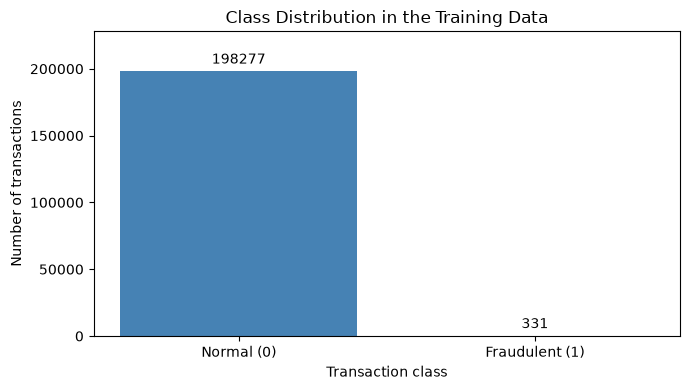

In [9]:
# Create a table for exploration using training data only
fraud_train_eda = X_train_fraud.copy()
fraud_train_eda["Class"] = y_train_fraud

# Summarize all 30 input features
print("TRAINING FEATURE SUMMARY")
display(X_train_fraud.describe().T.round(2))

# Compare transaction amounts between the two classes
print("\nTRANSACTION AMOUNTS BY CLASS: 0 = NORMAL, 1 = FRAUD")
amount_summary = fraud_train_eda.groupby("Class")["Amount"].describe()
display(amount_summary.round(2))

# Plot the number of transactions in each class
class_counts = y_train_fraud.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Normal (0)", "Fraudulent (1)"],
    class_counts.values,
    color=["steelblue", "tomato"]
)

ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Class Distribution in the Training Data")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions")
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

### Training Data Findings

The training data contains 198,277 normal transactions and 331 fraudulent transactions. The bar chart clearly shows the strong class imbalance.

Normal transactions have an average amount of 88.27 and a median of 22.09. Fraudulent transactions have a higher average of 116.96 but a lower median of 9.21. This suggests that some larger fraudulent transactions pull the average upward, while many fraudulent transactions involve small amounts.

The largest normal transaction is 18,910.00, compared with 2,125.87 for fraudulent transactions. Therefore, a high amount alone does not identify fraud.

The features also have different scales. For example, Time reaches 172,792, while many other feature values are much smaller. I will standardize the input features before fitting logistic regression.

I will retain unusually large values because they may represent valid transactions, and unusual patterns may be useful for detecting fraud.

## A6. Standardizing the Features

I use StandardScaler to put the input features on comparable scales. This helps logistic regression train and makes its regularization less dependent on the original units of each feature.

The scaler learns the mean and standard deviation from the training data only. It then applies those same values to both the training and testing data.

This prevents information from the test set from influencing preprocessing. The target labels are not scaled.

In [10]:
from sklearn.preprocessing import StandardScaler

# Learn scaling values from training features only
fraud_scaler = StandardScaler()

X_train_fraud_scaled = fraud_scaler.fit_transform(X_train_fraud)

# Apply the same training-based scaling to the test features
X_test_fraud_scaled = fraud_scaler.transform(X_test_fraud)

print("Scaled training shape:", X_train_fraud_scaled.shape)
print("Scaled testing shape:", X_test_fraud_scaled.shape)

# Check the training means and standard deviations after scaling
scaling_check = pd.DataFrame({
    "Feature": X_train_fraud.columns,
    "Mean after scaling": X_train_fraud_scaled.mean(axis=0),
    "Standard deviation after scaling": X_train_fraud_scaled.std(axis=0)
})

display(scaling_check.round(3))

Scaled training shape: (198608, 30)
Scaled testing shape: (85118, 30)


,Feature,Mean after scaling,Standard deviation after scaling
0,Time,-0.0,1.0
1,V1,0.0,1.0
2,V2,0.0,1.0
3,V3,-0.0,1.0
4,V4,-0.0,1.0
5,V5,-0.0,1.0
6,V6,-0.0,1.0
7,V7,-0.0,1.0
8,V8,-0.0,1.0
9,V9,0.0,1.0


## A7. Training the Logistic Regression Model

I train a logistic regression model using the standardized training features and their corresponding Class labels.

Although its name contains “regression,” logistic regression is used here for binary classification: normal (0) or fraudulent (1).

I first train a standard model without class weighting as a starting point. Because the dataset is highly imbalanced, I will check fraud detection performance alongside overall accuracy.

I allow up to 1,000 optimization iterations so the model has enough opportunity to converge. The test data is not used during training.

In [11]:
from sklearn.linear_model import LogisticRegression

# Create the logistic regression model
fraud_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000
)

# Learn from the training features and their correct labels
fraud_model.fit(X_train_fraud_scaled, y_train_fraud)

print("Model training completed.")
print("Classes learned:", fraud_model.classes_)
print("Number of input features:", fraud_model.n_features_in_)
print("Optimization iterations used:", fraud_model.n_iter_[0])

Model training completed.
Classes learned: [0 1]
Number of input features: 30
Optimization iterations used: 16


## A8. Evaluating the Logistic Regression Model

I use the trained model to predict the labels of the test transactions. I compare these predictions with the actual labels using four metrics:

- **Accuracy:** The proportion of all transactions classified correctly.
- **Precision:** Of the transactions flagged as fraud, how many were actually fraudulent?
- **Recall:** Of all actual fraudulent transactions, how many did the model detect?
- **F1-score:** A measure that combines precision and recall.

Precision, recall, and F1-score are calculated with fraud (Class 1) as the positive class.

I also compare the model's accuracy with a simple baseline that predicts every transaction as normal. This helps show why accuracy alone can be misleading for this dataset.

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict the labels of unseen test transactions
y_pred_fraud = fraud_model.predict(X_test_fraud_scaled)

# Baseline: predict every transaction as normal
y_pred_baseline = np.zeros_like(y_test_fraud)

# Compare both approaches using the same test set
fraud_results = pd.DataFrame({
    "Model": ["Always predict normal", "Logistic regression"],
    "Accuracy": [
        accuracy_score(y_test_fraud, y_pred_baseline),
        accuracy_score(y_test_fraud, y_pred_fraud)
    ],
    "Fraud precision": [
        precision_score(y_test_fraud, y_pred_baseline, zero_division=0),
        precision_score(y_test_fraud, y_pred_fraud, zero_division=0)
    ],
    "Fraud recall": [
        recall_score(y_test_fraud, y_pred_baseline, zero_division=0),
        recall_score(y_test_fraud, y_pred_fraud, zero_division=0)
    ],
    "Fraud F1": [
        f1_score(y_test_fraud, y_pred_baseline, zero_division=0),
        f1_score(y_test_fraud, y_pred_fraud, zero_division=0)
    ]
}).set_index("Model")

display(fraud_results.round(4))

print(
    f"\nLogistic regression test accuracy: "
    f"{accuracy_score(y_test_fraud, y_pred_fraud):.2%}"
)
print("Actual fraudulent transactions:", int(y_test_fraud.sum()))
print("Transactions predicted as fraud:", int(y_pred_fraud.sum()))

,Accuracy,Fraud precision,Fraud recall,Fraud F1
Model,,,,
Always predict normal,0.9983,0.0000,0.0000,0.0000
Logistic regression,0.9991,0.8404,0.5563,0.6695



Logistic regression test accuracy: 99.91%
Actual fraudulent transactions: 142
Transactions predicted as fraud: 94


### Logistic Regression Evaluation Findings

Logistic regression achieved approximately 99.91% test accuracy, compared with 99.83% for the baseline that classified every transaction as normal.

However, the baseline detected no fraud. Logistic regression achieved fraud precision of 84.04%, recall of 55.63%, and an F1-score of 0.6695.

The model's fraud alerts were mostly correct, but it missed approximately 44.37% of actual fraudulent transactions. Therefore, its high overall accuracy does not mean that fraud detection is fully reliable.

## A9. Confusion Matrix

I use a confusion matrix to examine four types of prediction:

- **True negatives:** Normal transactions correctly classified as normal.
- **False positives:** Normal transactions incorrectly flagged as fraud.
- **False negatives:** Fraudulent transactions incorrectly classified as normal.
- **True positives:** Fraudulent transactions correctly detected.

False negatives represent missed fraud, while false positives represent false alarms that could inconvenience customers.

Normal transactions correctly classified: 84961
Normal transactions incorrectly flagged as fraud: 15
Fraudulent transactions missed: 63
Fraudulent transactions correctly detected: 79


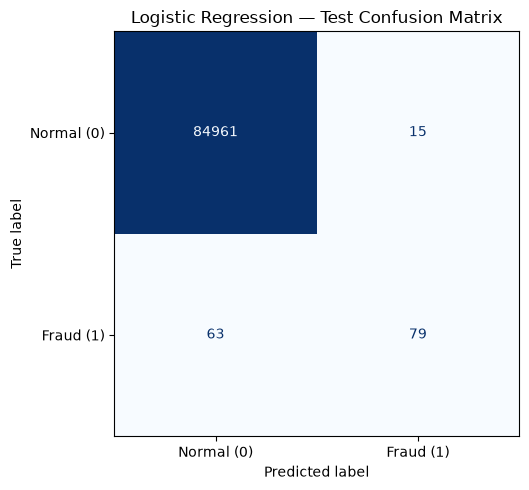

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Rows are actual labels; columns are predicted labels
fraud_cm = confusion_matrix(
    y_test_fraud,
    y_pred_fraud,
    labels=[0, 1]
)

tn, fp, fn, tp = fraud_cm.ravel()

print("Normal transactions correctly classified:", tn)
print("Normal transactions incorrectly flagged as fraud:", fp)
print("Fraudulent transactions missed:", fn)
print("Fraudulent transactions correctly detected:", tp)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=fraud_cm,
    display_labels=["Normal (0)", "Fraud (1)"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Logistic Regression — Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Confusion Matrix Findings

The model correctly classified 84,961 normal transactions and detected 79 fraudulent transactions. It incorrectly flagged 15 normal transactions as fraud and missed 63 fraudulent transactions.

These results explain why accuracy alone is insufficient. Although overall accuracy was approximately 99.91%, the model missed 63 of the 142 actual frauds.

The model produced relatively few false alarms, but its ability to detect fraud was limited. Future improvements could investigate class weighting or a different decision threshold, using validation data from the training set rather than tuning on the test set.

# Part B: Insurance Cost Prediction

## B1. Loading and Previewing the Dataset

In this part, I will use linear regression to predict insurance costs.

The target column is `charges`. The other columns describe characteristics that may help predict these charges.

I first load the dataset, check its size, and preview the first five rows. I will then inspect data quality, explore the training data, prepare the features, train the model, and evaluate its predictions using a 70% training and 30% testing split.

In [14]:
# Load the insurance dataset
insurance_df = pd.read_csv(data_folder / "insurance.csv")

print("Number of rows:", insurance_df.shape[0])
print("Number of columns:", insurance_df.shape[1])

print("\nColumn names:")
print(insurance_df.columns.tolist())

display(insurance_df.head())

Number of rows: 1338
Number of columns: 7

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## B2. Checking Data Quality

The insurance dataset contains 1,338 rows and 7 columns. The target is `charges`, and the remaining six columns are input features.

I check the data types, missing values, exact duplicate rows, and category labels before making any changes.

The columns `sex`, `smoker`, and `region` contain text categories. These will need to be encoded as numerical features before training linear regression.

In [15]:
# Show data types and missing-value counts together
insurance_quality = pd.DataFrame({
    "Data type": insurance_df.dtypes.astype(str),
    "Missing values": insurance_df.isna().sum()
})

display(insurance_quality)

# Count exact repeated rows
print("Exact duplicate rows:", insurance_df.duplicated().sum())

# Inspect the text categories
print("\nCATEGORY COUNTS")
for column in ["sex", "smoker", "region"]:
    print(f"\n{column}:")
    print(insurance_df[column].value_counts(dropna=False))

# Check basic numerical ranges
print("\nNUMERICAL RANGES")
display(
    insurance_df[["age", "bmi", "children", "charges"]]
    .agg(["min", "max"])
)

,Data type,Missing values
age,int64,0
sex,str,0
bmi,float64,0
children,int64,0
smoker,str,0
region,str,0
charges,float64,0


Exact duplicate rows: 1

CATEGORY COUNTS

sex:
sex
male      676
female    662
Name: count, dtype: int64

smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

NUMERICAL RANGES


,age,bmi,children,charges
min,18,15.96,0,1121.87390
max,64,53.13,5,63770.42801


## B3. Handling Duplicates and Splitting the Data

There are no missing values, and the category labels are consistent. The numerical ranges do not show obvious invalid values.

I found one exact duplicate row. I keep its first occurrence and remove the repeated copy to prevent identical records from appearing in both training and testing data. However, without a unique person ID, I cannot confirm whether these records represent the same person.

I separate `charges` as the target and use the other six columns as input features. I split the cleaned data into 70% training and 30% testing, using `random_state=42` for reproducibility.

Unlike Part A, the target is a continuous numerical value, so I do not stratify by the target. Further exploration and preprocessing will use the training data.

In [16]:
# Remove exact repeated copies while preserving the original data
insurance_clean = insurance_df.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(insurance_df))
print("Rows removed:", len(insurance_df) - len(insurance_clean))
print("Remaining rows:", len(insurance_clean))
print("Remaining exact duplicates:", insurance_clean.duplicated().sum())

# Separate the input features and target
X_insurance = insurance_clean.drop(columns="charges")
y_insurance = insurance_clean["charges"]

# Split into 70% training and 30% testing
X_train_insurance, X_test_insurance, y_train_insurance, y_test_insurance = (
    train_test_split(
        X_insurance,
        y_insurance,
        test_size=0.30,
        random_state=42
    )
)

print("\nTraining feature shape:", X_train_insurance.shape)
print("Testing feature shape:", X_test_insurance.shape)
print("Training target shape:", y_train_insurance.shape)
print("Testing target shape:", y_test_insurance.shape)

Original rows: 1338
Rows removed: 1
Remaining rows: 1337
Remaining exact duplicates: 0

Training feature shape: (935, 6)
Testing feature shape: (402, 6)
Training target shape: (935,)
Testing target shape: (402,)


## B4. Exploring the Training Data

I explore the training data while keeping the test set reserved for evaluation.

I calculate summary statistics for the numerical columns and compare charges between smokers and non-smokers.

I also create two graphs:
- A histogram showing the distribution of charges.
- A scatter plot showing age and charges, with colours identifying smoking status.

These comparisons show associations in this dataset. They do not prove that one characteristic causes a particular cost.

TRAINING DATA SUMMARY


,age,bmi,children,charges
count,935.00,935.00,935.00,935.00
mean,39.01,30.62,1.08,13035.07
std,14.00,6.02,1.20,11659.16
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4718.86
50%,39.00,30.21,1.00,9283.56
75%,51.00,34.64,2.00,16830.61
max,64.00,53.13,5.00,58571.07



CHARGES BY SMOKING STATUS


,count,mean,median,min,max
smoker,,,,,
no,741,8407.91,7261.74,1121.87,36910.61
yes,194,30708.90,31745.27,12829.46,58571.07


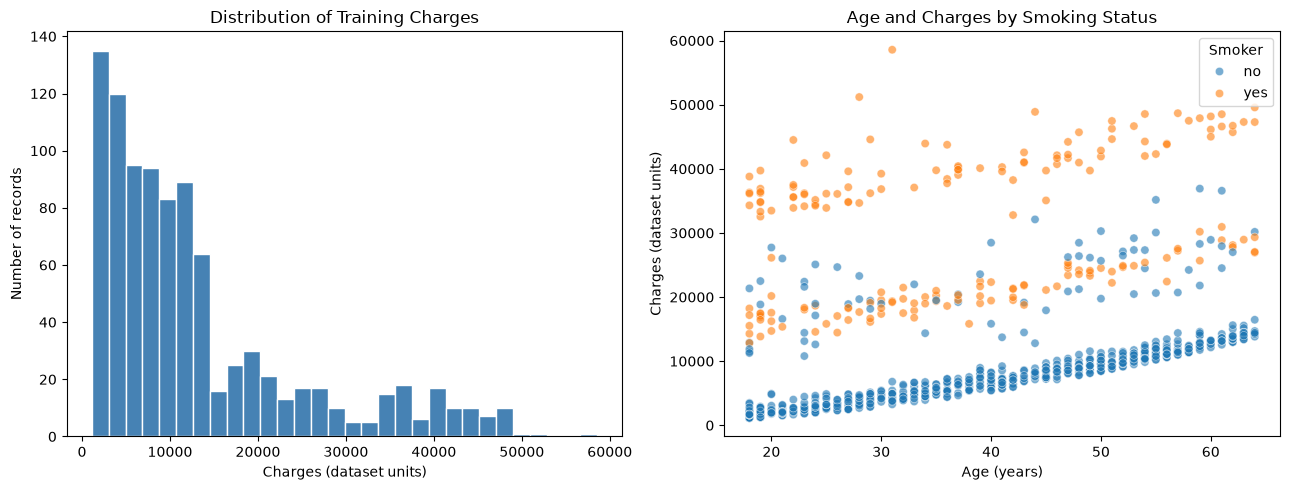

In [17]:
# Combine training features and targets for exploration
insurance_train_eda = X_train_insurance.copy()
insurance_train_eda["charges"] = y_train_insurance

# Summarize the numerical columns
print("TRAINING DATA SUMMARY")
display(insurance_train_eda.describe().round(2))

# Compare charges by smoking status
print("\nCHARGES BY SMOKING STATUS")
smoking_summary = (
    insurance_train_eda.groupby("smoker")["charges"]
    .agg(["count", "mean", "median", "min", "max"])
)
display(smoking_summary.round(2))

# Create two exploratory graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    insurance_train_eda["charges"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)
axes[0].set_title("Distribution of Training Charges")
axes[0].set_xlabel("Charges (dataset units)")
axes[0].set_ylabel("Number of records")

sns.scatterplot(
    data=insurance_train_eda,
    x="age",
    y="charges",
    hue="smoker",
    hue_order=["no", "yes"],
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Age and Charges by Smoking Status")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Charges (dataset units)")
axes[1].legend(title="Smoker")

plt.tight_layout()
plt.show()

### Training Data Findings

The average training charge is 13,035.07, while the median is 9,283.56. The histogram is right-skewed: most records have lower charges, while a smaller number have much higher charges.

The training set contains 741 non-smokers and 194 smokers. Average charges are 8,407.91 for non-smokers and 30,708.90 for smokers.

The scatter plot suggests that charges generally increase with age and that smokers often have higher charges. However, there is considerable variation, so these characteristics do not determine an exact cost.

I retain the high charges because there is no evidence that they are recording errors.

## B5. Encoding Categorical Features

Linear regression requires numerical inputs. I use one-hot encoding for `sex`, `smoker`, and `region`.

I drop one category from each feature to use as a reference category. This avoids redundant indicator columns when fitting linear regression with an intercept.

The encoder learns the categories from the training data only and applies the same mapping to the test data. The numerical features `age`, `bmi`, and `children` are passed through unchanged.

Standardization is not required for this ordinary least-squares linear regression model. Charges remain in their original units.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

# Encode text columns and retain the existing numerical columns
insurance_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categories",
            OneHotEncoder(drop="first", sparse_output=False),
            categorical_features
        ),
        ("numbers", "passthrough", numerical_features)
    ],
    verbose_feature_names_out=False
)

# Learn category mappings from training data only
X_train_insurance_encoded = insurance_preprocessor.fit_transform(
    X_train_insurance
)

# Apply the same mappings to the test data
X_test_insurance_encoded = insurance_preprocessor.transform(
    X_test_insurance
)

encoded_feature_names = insurance_preprocessor.get_feature_names_out()

print("Encoded training shape:", X_train_insurance_encoded.shape)
print("Encoded testing shape:", X_test_insurance_encoded.shape)

print("\nEncoded feature names:")
print(encoded_feature_names.tolist())

# Preview the numerical inputs that the model will receive
display(
    pd.DataFrame(
        X_train_insurance_encoded,
        columns=encoded_feature_names,
        index=X_train_insurance.index
    ).head()
)

Encoded training shape: (935, 8)
Encoded testing shape: (402, 8)

Encoded feature names:
['sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'age', 'bmi', 'children']


,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,age,bmi,children
138,0.0,0.0,0.0,1.0,0.0,54.0,31.900,3.0
381,1.0,1.0,0.0,0.0,0.0,55.0,30.685,0.0
292,1.0,1.0,0.0,1.0,0.0,25.0,45.540,2.0
1089,1.0,1.0,0.0,1.0,0.0,47.0,36.190,0.0
892,1.0,1.0,0.0,1.0,0.0,47.0,38.940,2.0


## B6. Training the Linear Regression Model

After encoding, the dataset has eight numerical input features.

I train a linear regression model using the training features and their corresponding charges. The model learns coefficients that minimize the sum of squared differences between actual and predicted training charges.

Each coefficient describes how the prediction changes when that feature increases by one unit, while the other input features remain fixed. For categorical indicators, the coefficient represents a difference from the reference category.

These coefficients describe relationships learned from the dataset, not proven causal effects. The test data is not used during training.

In [19]:
from sklearn.linear_model import LinearRegression

# Create and train the model
insurance_model = LinearRegression()

insurance_model.fit(
    X_train_insurance_encoded,
    y_train_insurance
)

print("Linear regression training completed.")
print("Number of input features:", insurance_model.n_features_in_)
print("Intercept:", round(insurance_model.intercept_, 2))

# Display the learned weight for each feature
insurance_coefficients = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Coefficient": insurance_model.coef_
})

display(insurance_coefficients.round(2))

Linear regression training completed.
Number of input features: 8
Intercept: -11516.78


,Feature,Coefficient
0,sex_male,-111.91
1,smoker_yes,22874.45
2,region_northwest,-465.75
3,region_southeast,-936.10
4,region_southwest,-765.58
5,age,251.25
6,bmi,328.38
7,children,522.16


### Model Coefficient Findings

Holding the other features constant, the model predicts an increase of 251.25 charge units for each additional year of age, 328.38 for each additional BMI unit, and 522.16 for each additional child.

The smoker indicator adds 22,874.45 charge units compared with a non-smoker with otherwise identical inputs.

The regional coefficients are comparisons with northeast, and the sex coefficient compares male with female. These are model associations, not causal conclusions.

The intercept is -11,516.78. It represents the prediction for the reference categories when all numerical inputs are zero. Since age and BMI equal to zero are outside the training data, this value should not be interpreted as a realistic standalone insurance cost.

## B7. Evaluating Insurance Cost Predictions

I predict charges for the test set and evaluate them using:

- **MAE:** The average absolute prediction error, in the original charge units.
- **MSE:** The average squared prediction error, in squared charge units.
- **RMSE:** The square root of MSE, expressed in the original charge units. It gives greater emphasis to large errors than MAE.
- **R²:** Measures performance relative to predicting the test-set mean. A value of 1 indicates perfect predictions, 0 matches that reference, and negative values indicate worse performance.

R² is not a percentage accuracy score.

I also compare the model with a baseline that predicts the training-set average charge for every test record. This baseline uses no information from the test targets during fitting.

In [20]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict charges for the unseen test records
y_pred_insurance = insurance_model.predict(X_test_insurance_encoded)

# Baseline: predict the training-set average for every test record
insurance_baseline_pred = np.full(
    len(y_test_insurance),
    y_train_insurance.mean()
)

# Evaluate both approaches
insurance_results = []

for model_name, predictions in [
    ("Training mean baseline", insurance_baseline_pred),
    ("Linear regression", y_pred_insurance)
]:
    mse = mean_squared_error(y_test_insurance, predictions)

    insurance_results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test_insurance, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_test_insurance, predictions)
    })

insurance_results = pd.DataFrame(insurance_results).set_index("Model")
display(insurance_results.round(4))

# Inspect a few individual predictions
insurance_predictions = pd.DataFrame({
    "Actual charges": y_test_insurance,
    "Predicted charges": y_pred_insurance
})

insurance_predictions["Absolute error"] = (
    insurance_predictions["Actual charges"]
    - insurance_predictions["Predicted charges"]
).abs()

print("\nFIRST FIVE TEST PREDICTIONS")
display(insurance_predictions.head().round(2))

print(
    "\nNumber of negative predicted charges:",
    int((y_pred_insurance < 0).sum())
)

,MAE,MSE,RMSE,R²
Model,,,,
Training mean baseline,9423.6573,1.717766e+08,13106.3558,-0.0039
Linear regression,4181.8160,3.894017e+07,6240.2059,0.7724



FIRST FIVE TEST PREDICTIONS


,Actual charges,Predicted charges,Absolute error
899,8688.86,8075.92,612.94
1063,5708.87,5499.00,209.86
1255,11436.74,14345.71,2908.97
298,38746.36,31428.20,7318.15
237,4463.21,8874.78,4411.58



Number of negative predicted charges: 7


### Insurance Model Evaluation Findings

Linear regression achieved a test MAE of 4,181.82 and RMSE of 6,240.21. Both are lower than the baseline values of 9,423.66 and 13,106.36, respectively.

The model achieved an R² of 0.7724, explaining approximately 77.24% of the variation in test charges. This is not a percentage accuracy score.

RMSE is higher than MAE, indicating that some predictions have relatively large errors. The model also produced seven negative predictions, which are not realistic insurance charges.

I keep these predictions unchanged when calculating the metrics to report the model's original performance honestly. The results show that linear regression is useful as a starting point, but it has limitations.

## B8. Visual Evaluation of Predictions

I plot actual charges against predicted charges. The diagonal reference line represents perfect predictions.

I also plot residuals against predicted charges. A residual is the actual charge minus the predicted charge. Ideally, residuals would be scattered around zero without a clear pattern.

These plots help identify large errors, systematic prediction patterns, and limitations of the linear model. They are used to assess the model, not to tune it on the test set.

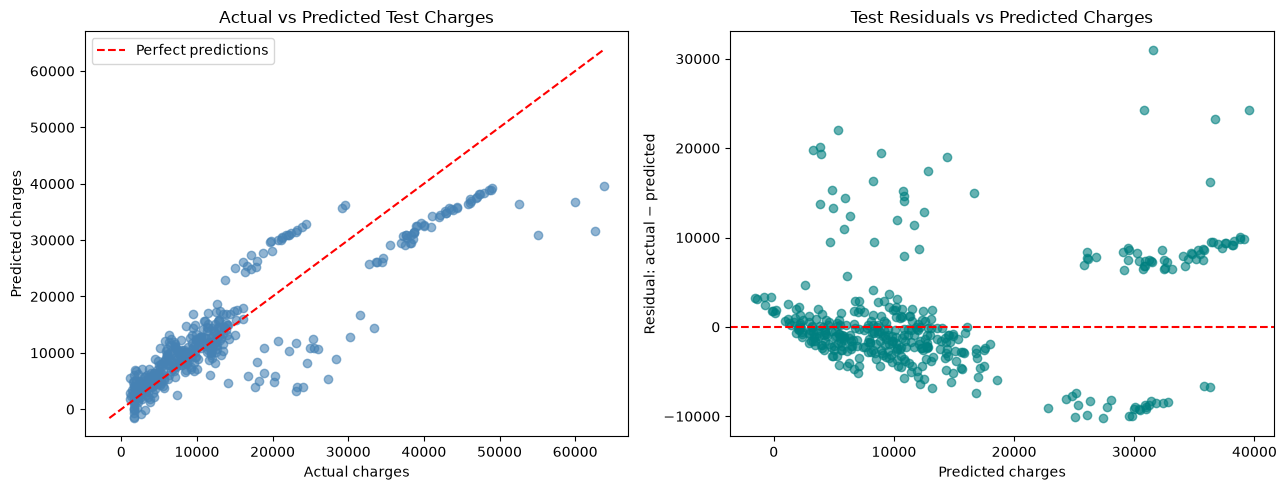

In [21]:
# Positive residual = underprediction
# Negative residual = overprediction
insurance_residuals = y_test_insurance.to_numpy() - y_pred_insurance

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual versus predicted charges
axes[0].scatter(
    y_test_insurance,
    y_pred_insurance,
    alpha=0.6,
    color="steelblue"
)

lower = min(y_test_insurance.min(), y_pred_insurance.min())
upper = max(y_test_insurance.max(), y_pred_insurance.max())

axes[0].plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect predictions"
)

axes[0].set_title("Actual vs Predicted Test Charges")
axes[0].set_xlabel("Actual charges")
axes[0].set_ylabel("Predicted charges")
axes[0].legend()

# Residuals versus predicted charges
axes[1].scatter(
    y_pred_insurance,
    insurance_residuals,
    alpha=0.6,
    color="teal"
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Test Residuals vs Predicted Charges")
axes[1].set_xlabel("Predicted charges")
axes[1].set_ylabel("Residual: actual − predicted")

plt.tight_layout()
plt.show()

### Visual Evaluation Findings

Many predictions are close to the diagonal reference line, especially for lower charges. However, several high-cost records fall well below the line, meaning the model underestimates their charges.

The residual plot shows clear groups and uneven error sizes rather than random scatter around zero. This suggests that the simple linear model does not fully capture the patterns in the data.

Possible future improvements include investigating nonlinear relationships or interactions between features. Any improvements should be developed using validation data from the training set, rather than using the test set to choose changes.

# Conclusion

## Part A: Credit Card Fraud Detection

I used logistic regression to classify credit card transactions after checking data quality, removing exact duplicate copies, and standardizing the features. I used a stratified 70/30 train-test split and fitted the scaler using training data only.

The model achieved approximately 99.91% test accuracy. However, it detected only 79 of the 142 fraudulent transactions, missed 63, and produced 15 false alarms. Fraud precision was 84.04%, recall was 55.63%, and the F1-score was 0.6695.

This showed me why accuracy alone can be misleading when most transactions belong to one class. The model detected some fraud successfully, but its missed-fraud rate remains a major limitation.

## Part B: Insurance Cost Prediction

I used linear regression to predict insurance charges. I checked data quality, removed one exact duplicate copy, and used a 70/30 train-test split. I encoded categorical features using mappings learned from the training data only.

The model achieved a test MAE of 4,181.82, RMSE of 6,240.21, and R² of 0.7724. It performed better than predicting the training-set average charge for every record.

However, it produced seven negative predictions and underestimated several high charges. The residual patterns also showed that the model did not fully capture the relationships in the data.

## Overall Learning

This lab helped me understand the difference between classification and regression. Classification predicts a category, while regression predicts a numerical value. I also learned to prevent data leakage, compare models with simple baselines, and explain limitations alongside performance scores.

The results come from one train-test split, so performance may vary with a different split or new data. Removing exact duplicates was a documented assumption because neither dataset provided a unique identifier that could confirm whether identical rows represented separate records.

# References

- Credit Card Fraud Detection dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Insurance dataset: https://www.kaggle.com/datasets/mirichoi0218/insurance
- GitHub Pages instructions: https://docs.github.com/en/pages/quickstart